# E-Commerce Sales & Customer Analytics — Exploratory Analysis

**Dataset** Indian E-Commerce Customer & Order Intelligence (synthetic, 2023-01-01 → 2025-12-31)
**Grain** one row per order line item — 254,331 rows × 83 columns
**Author** Rakesh Mythreya Vulli · Data Analyst

---

## Purpose

Answer nine business questions in one place:

1. What is total revenue and profit?
2. Which products generate the most revenue?
3. Which categories have the highest margin?
4. Which regions perform best?
5. What are the monthly / quarterly trends?
6. Who are the highest-value customers?
7. Which customers are repeat vs one-time?
8. What should management focus on?
9. Are there seasonal patterns?

## Definition used throughout

All revenue figures are **realised revenue** — `Delivered + Returned` orders only, at **item level**
(excludes shipping and tax). This is decision C from the data audit:

| Definition | Revenue | Orders |
|---|---:|---:|
| All orders | ₹2.450 Bn | 100,000 |
| Excluding `Failed` (order book) | ₹2.382 Bn | 97,120 |
| **Realised (Delivered + Returned)** | **₹2.147 Bn** | **87,360** |

The ₹303 M gap between "all orders" and "realised" is cancelled / failed / in-processing demand that never converted. Locking one definition is what stops the same dashboard showing three different revenue numbers.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")

# Paths: work whether the kernel starts in the project root or in python/
PROJ = Path.cwd()
if not (PROJ / "data" / "cleaned_data.csv").exists():
    PROJ = PROJ.parent
DATA, FIG = PROJ / "data", PROJ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Chart theme
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (12, 5), "figure.dpi": 110,
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "DejaVu Sans",
})
PALETTE = ["#2E5A88", "#E8833A", "#4B9B6B", "#B5495B", "#7D6B9E", "#8C8C8C"]
sns.set_palette(PALETTE)

CURR = lambda v, pos=None: f"₹{v/1e7:,.0f} Cr"   # rupees -> crore
print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")


pandas 2.3.3 | numpy 2.3.5 | matplotlib 3.10.6


## 1 · Load and sanity-check the analysis base

`cleaned_data.csv` is the order-item fact table produced by `sql/01_data_cleaning.sql`'s rules.
Before touching a single KPI, confirm the row count and the revenue total match the audited
baseline — if they don't, everything downstream is wrong.

In [2]:
df = pd.read_csv(DATA / "cleaned_data.csv", parse_dates=["order_date"], low_memory=False)

print(f"shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"date range: {df.order_date.min():%Y-%m-%d} -> {df.order_date.max():%Y-%m-%d}")
print(f"orders: {df.order_id.nunique():,} | customers: {df.customer_id.nunique():,} | products: {df.product_id.nunique():,}")

# Integrity gate: must equal the SQL baseline (2,146,672,724.50)
realised = df[df.is_realised == 1]
print(f"\nrealised revenue (item level): Rs {realised.line_revenue.sum():,.2f}")
print(f"realised profit:               Rs {realised.line_profit.sum():,.2f}")
print(f"\nnull check on critical columns:")
crit = ["order_date","customer_id","product_id","line_revenue","line_profit","region","order_status"]
print(df[crit].isna().sum().to_string())

shape: 254,331 rows x 83 columns
date range: 2023-01-01 -> 2025-12-31


orders: 100,000 | customers: 22,820 | products: 550



realised revenue (item level): Rs 2,146,672,724.50
realised profit:               Rs 172,348,561.12

null check on critical columns:
order_date      0
customer_id     0
product_id      0
line_revenue    0
line_profit     0
region          0
order_status    0


## 2 · Q1 — Total revenue and profit

The headline scorecard. Note the **8.0% blended margin**: in this business ₹100 of merchandise
revenue leaves ₹8 of gross profit, so every discount point is expensive.

In [3]:
kpi = pd.Series({
    "Realised revenue":        realised.line_revenue.sum(),
    "Realised cost":           realised.line_cost.sum(),
    "Gross profit":            realised.line_profit.sum(),
    "Blended margin %":        realised.line_profit.sum() / realised.line_revenue.sum() * 100,
    "Orders":                  realised.order_id.nunique(),
    "Buying customers":        realised.customer_id.nunique(),
    "Units sold":              realised.quantity.sum(),
    "Average order value":     realised.line_revenue.sum() / realised.order_id.nunique(),
    "Revenue per customer":    realised.line_revenue.sum() / realised.customer_id.nunique(),
    "Lost orders (Canc+Fail)": int((df.is_lost_sale == 1).groupby(df.order_id).first().sum()),
    "Lost revenue":            df.loc[df.is_lost_sale == 1, "line_revenue"].sum(),
})

fmt = {
    "Realised revenue": "{:,.0f}", "Realised cost": "{:,.0f}", "Gross profit": "{:,.0f}",
    "Blended margin %": "{:.2f}%", "Orders": "{:,.0f}", "Buying customers": "{:,.0f}",
    "Units sold": "{:,.0f}", "Average order value": "{:,.0f}",
    "Revenue per customer": "{:,.0f}", "Lost orders (Canc+Fail)": "{:,.0f}",
    "Lost revenue": "{:,.0f}",
}
for k, v in kpi.items():
    print(f"  {k:<26}{fmt[k].format(v):>18}")

  Realised revenue               2,146,672,724
  Realised cost                  1,974,324,163
  Gross profit                     172,348,561
  Blended margin %                       8.03%
  Orders                                87,360
  Buying customers                      22,208
  Units sold                           512,014
  Average order value                   24,573
  Revenue per customer                  96,662
  Lost orders (Canc+Fail)               10,953
  Lost revenue                     261,358,234


## 3 · Q5 — Monthly and quarterly trend

Two things to separate here:

- **Growth** — yearly revenue: 2023 ₹0.59 Bn → 2024 ₹0.58 Bn (flat) → 2025 ₹0.97 Bn (+68% YoY).
  The dramatic month-1-to-month-36 multiple (18.5×) is mostly the 2023 launch ramp, not organic growth.
- **Seasonality** — a repeating Q4 festival shape (Diwali/Dussehra + Christmas).

Plotting raw monthly revenue mixes both. The next cell separates them.

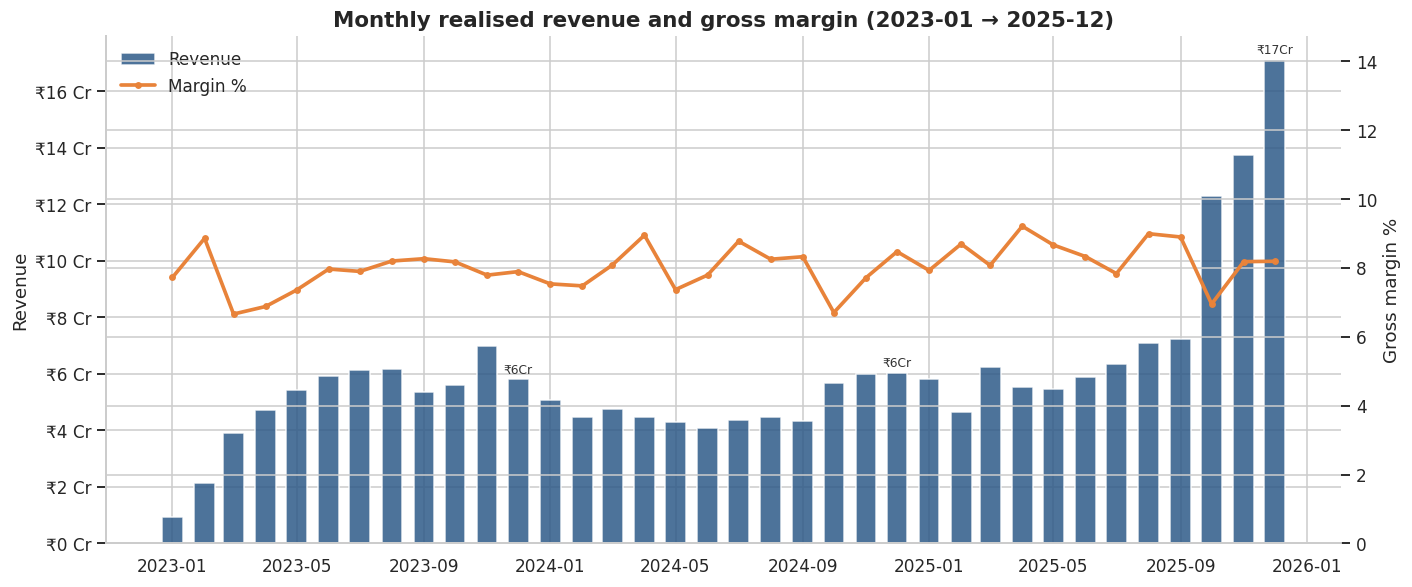

First month  2023-01:  revenue Rs 9,249,286
Last month   2025-12: revenue Rs 171,127,086
Growth multiple: 18.5x

Highest revenue months:
order_year_month      revenue  orders  margin_pct
         2025-12 171127086.10    6891    8.196292
         2025-11 137377180.30    5408    8.185533
         2025-10 122882586.05    5047    6.956177

Lowest revenue months:
order_year_month     revenue  orders  margin_pct
         2023-01  9249286.00     352    7.728500
         2023-02 21332703.50     858    8.862121
         2023-03 39206163.05    1492    6.663485


In [4]:
monthly = (df[df.is_realised == 1]
           .groupby("order_year_month", as_index=False)
           .agg(revenue=("line_revenue", "sum"),
                profit=("line_profit", "sum"),
                orders=("order_id", "nunique"),
                customers=("customer_id", "nunique")))
monthly["month_start"] = pd.to_datetime(monthly.order_year_month)
monthly["margin_pct"] = monthly.profit / monthly.revenue * 100
monthly["aov"] = monthly.revenue / monthly.orders
monthly = monthly.sort_values("month_start").reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(13, 5.5))
ax1.bar(monthly.month_start, monthly.revenue, width=20, color=PALETTE[0], alpha=.85, label="Revenue")
ax1.set_ylabel("Revenue")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(CURR))
ax1.set_title("Monthly realised revenue and gross margin (2023-01 → 2025-12)")

ax2 = ax1.twinx()
ax2.plot(monthly.month_start, monthly.margin_pct, color=PALETTE[1], lw=2.4, marker="o", ms=3.5,
         label="Margin %")
ax2.set_ylabel("Gross margin %")
ax2.set_ylim(0, monthly.margin_pct.max() * 1.6)
ax2.spines["top"].set_visible(False)

for x, y, v in zip(monthly.month_start, monthly.revenue, monthly.revenue):
    if x.month == 12:
        ax1.annotate(f"₹{v/1e7:,.0f}Cr", (x, y), textcoords="offset points", xytext=(0, 4),
                     ha="center", fontsize=8, color="#333")

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False)
plt.tight_layout(); plt.savefig(FIG / "01_monthly_revenue_trend.png", bbox_inches="tight"); plt.show()

print(f"First month  {monthly.order_year_month.iloc[0]}:  revenue Rs {monthly.revenue.iloc[0]:,.0f}")
print(f"Last month   {monthly.order_year_month.iloc[-1]}: revenue Rs {monthly.revenue.iloc[-1]:,.0f}")
print(f"Growth multiple: {monthly.revenue.iloc[-1] / monthly.revenue.iloc[0]:.1f}x")
print(f"\nHighest revenue months:")
print(monthly.nlargest(3, "revenue")[["order_year_month","revenue","orders","margin_pct"]]
      .to_string(index=False))
print(f"\nLowest revenue months:")
print(monthly.nsmallest(3, "revenue")[["order_year_month","revenue","orders","margin_pct"]]
      .to_string(index=False))

### Quarterly view

Q4 2025 alone is **20.1% of all revenue in three years** — a 4-quarter-window business living on a
festival quarter. That has a direct planning consequence: inventory and cash must peak in Oct–Dec.

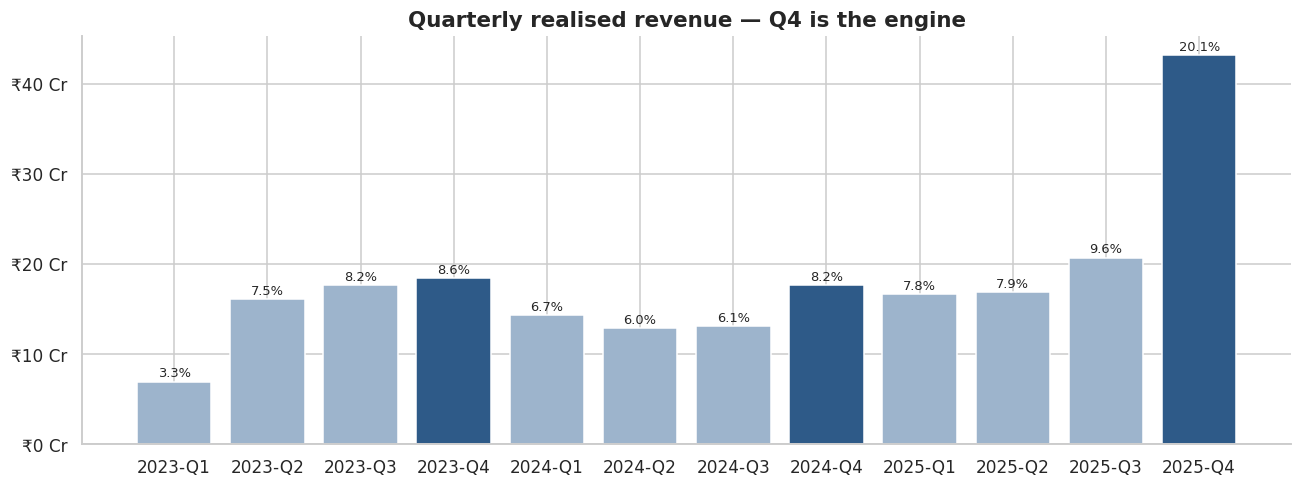

quarter   revenue  profit  orders  margin_pct      aov  pct_of_total
2023-Q1 ₹0.070 Bn ₹0.5 Cr    2702        7.48 25828.33          3.25
2023-Q2 ₹0.161 Bn ₹1.2 Cr    6474        7.45 24878.97          7.50
2023-Q3 ₹0.177 Bn ₹1.4 Cr    7165        8.12 24673.75          8.24
2023-Q4 ₹0.184 Bn ₹1.5 Cr    7481        7.94 24597.05          8.57
2024-Q1 ₹0.143 Bn ₹1.1 Cr    5752        7.70 24876.19          6.67
2024-Q2 ₹0.129 Bn ₹1.0 Cr    5396        8.06 23892.42          6.01
2024-Q3 ₹0.132 Bn ₹1.1 Cr    5373        8.45 24484.22          6.13
2024-Q4 ₹0.177 Bn ₹1.4 Cr    7350        7.65 24094.51          8.25
2025-Q1 ₹0.167 Bn ₹1.4 Cr    6710        8.20 24858.62          7.77
2025-Q2 ₹0.169 Bn ₹1.5 Cr    7064        8.73 23936.12          7.88
2025-Q3 ₹0.207 Bn ₹1.8 Cr    8547        8.61 24229.27          9.65
2025-Q4 ₹0.431 Bn ₹3.4 Cr   17346        7.84 24869.53         20.10


In [5]:
quarterly = (df[df.is_realised == 1]
             .assign(quarter=lambda d: d.order_year.astype(str) + "-Q" + d.order_quarter.astype(str))
             .groupby("quarter", as_index=False)
             .agg(revenue=("line_revenue","sum"), profit=("line_profit","sum"),
                  orders=("order_id","nunique")))
quarterly["margin_pct"] = quarterly.profit / quarterly.revenue * 100
quarterly["aov"] = quarterly.revenue / quarterly.orders
quarterly["pct_of_total"] = quarterly.revenue / quarterly.revenue.sum() * 100

fig, ax = plt.subplots(figsize=(12, 4.6))
bars = ax.bar(quarterly.quarter, quarterly.revenue, color=[PALETTE[0] if "Q4" in q else "#9DB4CC"
                                                         for q in quarterly.quarter])
ax.set_title("Quarterly realised revenue — Q4 is the engine")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"₹{v/1e7:,.0f} Cr"))
for b, v, p in zip(bars, quarterly.revenue, quarterly.pct_of_total):
    ax.annotate(f"{p:.1f}%", (b.get_x() + b.get_width()/2, v), textcoords="offset points",
                xytext=(0, 3), ha="center", fontsize=8.5)
plt.tight_layout(); plt.savefig(FIG / "02_quarterly_revenue.png", bbox_inches="tight"); plt.show()

display_q = quarterly.copy()
display_q["revenue"] = display_q.revenue.map(lambda v: f"₹{v/1e9:.3f} Bn")
display_q["profit"] = display_q.profit.map(lambda v: f"₹{v/1e7:.1f} Cr")
print(display_q.round(2).to_string(index=False))

## 4 · Q9 — Seasonal patterns

Pooling all three years by calendar month removes growth and leaves the *shape*.

The pattern is unambiguous: **Oct → Dec carries the year**, February is the trough.
Revenue per trading day is 2.5× higher in December than in January.

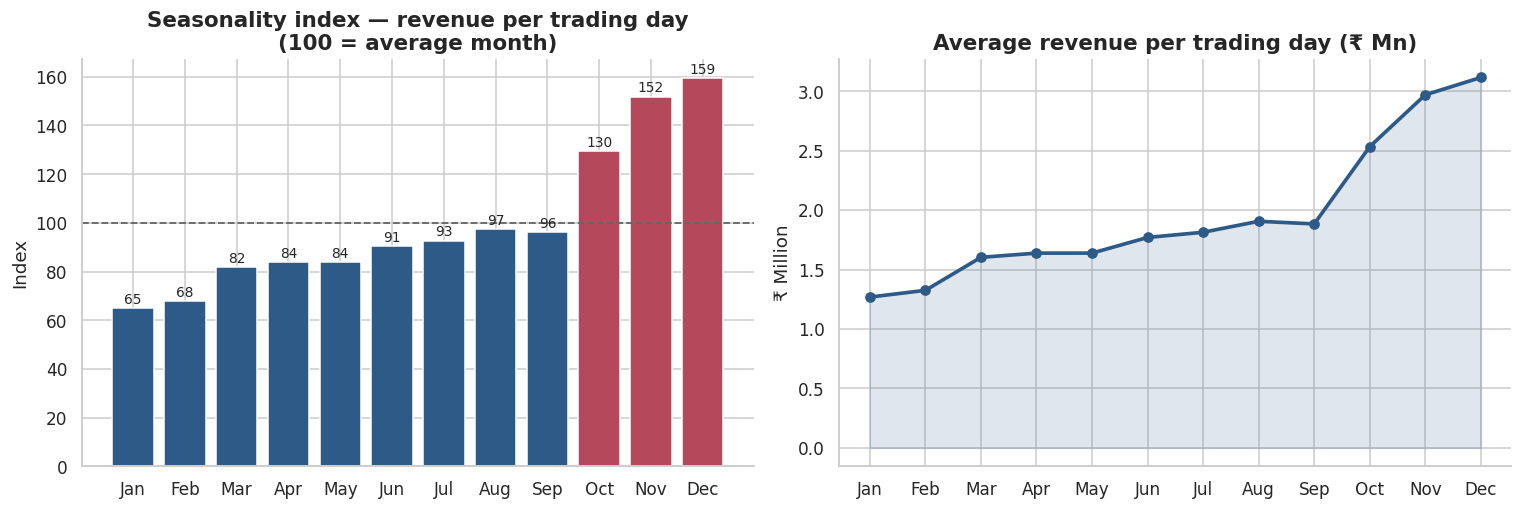

Peak month:   Dec  (Rs 3.11 Mn per trading day)
Trough month: Jan (Rs 1.27 Mn per trading day)
Peak/trough ratio: 2.46x



Q4 share of all revenue: 36.9%


In [6]:
seasonal = (df[df.is_realised == 1]
            .groupby(["order_month","order_month_name"], as_index=False)
            .agg(revenue=("line_revenue","sum"),
                 orders=("order_id","nunique"),
                 trading_days=("order_date","nunique")))
seasonal["avg_daily_revenue"] = seasonal.revenue / seasonal.trading_days
seasonal = seasonal.sort_values("order_month")
idx = seasonal.avg_daily_revenue / seasonal.avg_daily_revenue.mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

colors = ["#B5495B" if i >= 115 else ("#4B9B6B" if i >= 100 else "#2E5A88") for i in idx]
ax1.bar(seasonal.order_month_name, idx, color=colors)
ax1.axhline(100, color="#666", ls="--", lw=1.2)
ax1.set_title("Seasonality index — revenue per trading day\n(100 = average month)")
ax1.set_ylabel("Index")
for i, (n, v) in enumerate(zip(seasonal.order_month_name, idx)):
    ax1.annotate(f"{v:.0f}", (i, v), textcoords="offset points", xytext=(0, 3),
                 ha="center", fontsize=9)

ax2.plot(seasonal.order_month_name, seasonal.avg_daily_revenue / 1e6, marker="o", color=PALETTE[0], lw=2.4)
ax2.fill_between(seasonal.order_month_name, seasonal.avg_daily_revenue / 1e6, alpha=.15, color=PALETTE[0])
ax2.set_title("Average revenue per trading day (₹ Mn)")
ax2.set_ylabel("₹ Million")

plt.tight_layout(); plt.savefig(FIG / "03_seasonality.png", bbox_inches="tight"); plt.show()

peak, trough = seasonal.loc[seasonal.avg_daily_revenue.idxmax()], seasonal.loc[seasonal.avg_daily_revenue.idxmin()]
print(f"Peak month:   {peak.order_month_name}  (Rs {peak.avg_daily_revenue/1e6:.2f} Mn per trading day)")
print(f"Trough month: {trough.order_month_name} (Rs {trough.avg_daily_revenue/1e6:.2f} Mn per trading day)")
print(f"Peak/trough ratio: {peak.avg_daily_revenue/trough.avg_daily_revenue:.2f}x")
print(f"\nQ4 share of all revenue: "
      f"{df.loc[df.is_realised==1].groupby('order_quarter').line_revenue.sum().loc[4] / realised.line_revenue.sum() * 100:.1f}%")

## 5 · Q2 / Q3 — Products and categories: the central finding

**Electronics is 50% of revenue and 0.67% of margin.** Fashion is 5.7% of revenue and 33% of margin.
The business is buying revenue with profit.

The lower panel is the one that matters for management: profit contribution is almost the inverse
of revenue contribution.

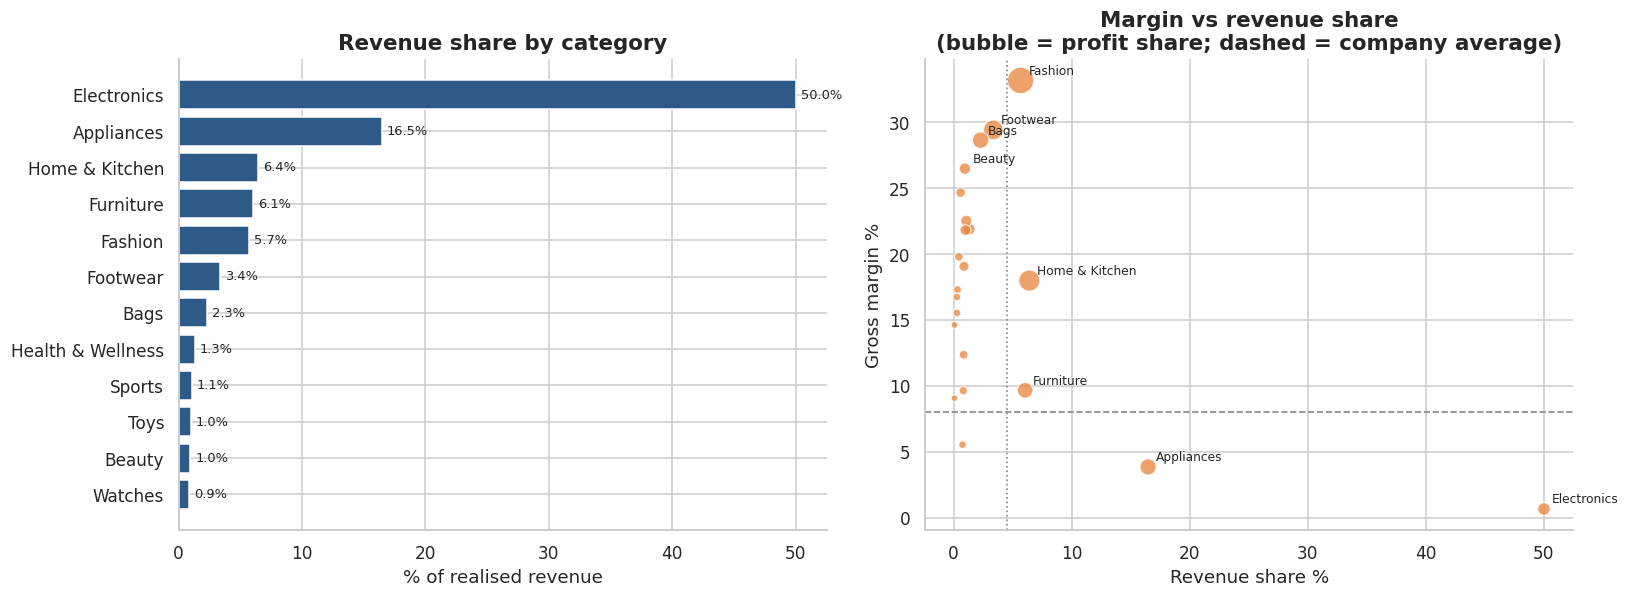

         category   revenue  profit  margin_pct  rev_share  profit_share  products
      Electronics ₹1.074 Bn ₹0.7 Cr        0.67      50.04          4.20        47
       Appliances ₹0.354 Bn ₹1.4 Cr        3.86      16.48          7.93        21
   Home & Kitchen ₹0.138 Bn ₹2.5 Cr       17.99       6.42         14.38        51
        Furniture ₹0.130 Bn ₹1.3 Cr        9.67       6.06          7.30        18
          Fashion ₹0.122 Bn ₹4.0 Cr       33.17       5.68         23.46        67
         Footwear ₹0.072 Bn ₹2.1 Cr       29.41       3.36         12.33        29
             Bags ₹0.049 Bn ₹1.4 Cr       28.64       2.28          8.14        30
Health & Wellness ₹0.028 Bn ₹0.6 Cr       21.91       1.31          3.57        26
           Sports ₹0.023 Bn ₹0.5 Cr       22.52       1.07          3.01        17
             Toys ₹0.021 Bn ₹0.5 Cr       21.82       1.00          2.71        25
           Beauty ₹0.020 Bn ₹0.5 Cr       26.48       0.95          3.14        29
    

In [7]:
cat = (df[df.is_realised == 1]
       .groupby("category", as_index=False)
       .agg(revenue=("line_revenue","sum"), profit=("line_profit","sum"),
            units=("quantity","sum"), orders=("order_id","nunique"),
            products=("product_id","nunique")))
cat["margin_pct"] = cat.profit / cat.revenue * 100
cat["rev_share"] = cat.revenue / cat.revenue.sum() * 100
cat["profit_share"] = cat.profit / cat.profit.sum() * 100
cat = cat.sort_values("revenue", ascending=False).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.6))

top = cat.head(12)
ax1.barh(top.category[::-1], top.rev_share[::-1], color=PALETTE[0])
ax1.set_title("Revenue share by category")
ax1.set_xlabel("% of realised revenue")
for i, v in enumerate(top.rev_share[::-1]):
    ax1.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=8.5)

profit_sorted = cat.sort_values("margin_pct", ascending=False)
ax2.scatter(cat.rev_share, cat.margin_pct, s=cat.profit_share * 12 + 18,
            color=PALETTE[1], alpha=.75, edgecolor="white", linewidth=.8)
for _, r in cat.iterrows():
    if r.rev_share > 3 or r.margin_pct > 25:
        ax2.annotate(r.category, (r.rev_share, r.margin_pct), textcoords="offset points",
                     xytext=(5, 4), fontsize=8)
ax2.axhline(cat.profit.sum()/cat.revenue.sum()*100, color="#888", ls="--", lw=1.1)
ax2.axvline(cat.rev_share.mean(), color="#888", ls=":", lw=1.1)
ax2.set_xlabel("Revenue share %"); ax2.set_ylabel("Gross margin %")
ax2.set_title("Margin vs revenue share\n(bubble = profit share; dashed = company average)")

plt.tight_layout(); plt.savefig(FIG / "04_category_performance.png", bbox_inches="tight"); plt.show()

show = cat.copy()
show["revenue"] = show.revenue.map(lambda v: f"₹{v/1e9:.3f} Bn")
show["profit"] = show.profit.map(lambda v: f"₹{v/1e7:.1f} Cr")
print(show[["category","revenue","profit","margin_pct","rev_share","profit_share","products"]]
      .round(2).head(12).to_string(index=False))

### Top 20 products by revenue — and the margin attached to each

Look at the profit column of the top rows. The #1 product (`PROD10246`, a ₹66,050 premium smartwatch)
is **21.4% of total company revenue** and earns a **1.45% margin** — because its cost is 85.8% of
list price and it is discounted ~13% on average. The single largest revenue driver is almost
profitless.

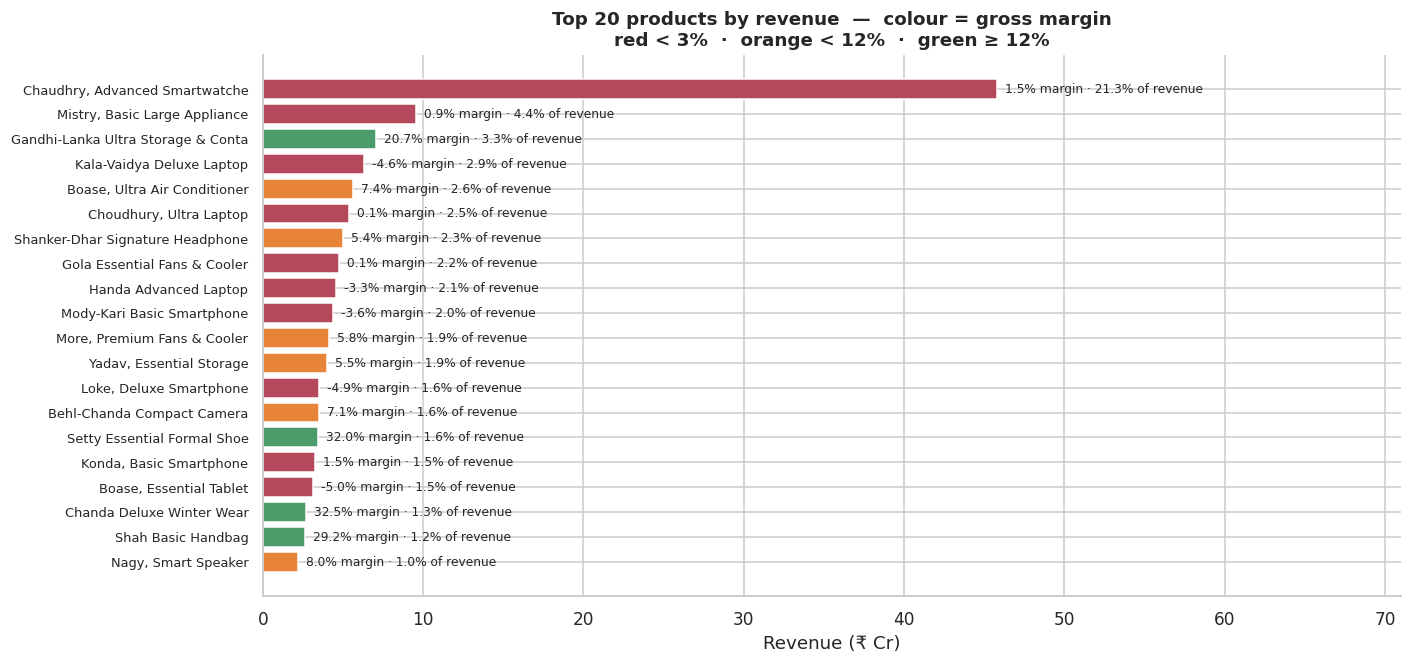

                          product_name       category  revenue    profit  margin_pct  rev_share  return_rate
        Chaudhry, Advanced Smartwatche    Electronics ₹45.8 Cr  ₹0.67 Cr        1.45      21.35          5.6
         Mistry, Basic Large Appliance     Appliances  ₹9.5 Cr  ₹0.08 Cr        0.88       4.44          5.8
Gandhi-Lanka Ultra Storage & Container Home & Kitchen  ₹7.1 Cr  ₹1.46 Cr       20.66       3.30          4.4
             Kala-Vaidya Deluxe Laptop    Electronics  ₹6.3 Cr ₹-0.29 Cr       -4.62       2.93          4.9
          Boase, Ultra Air Conditioner     Appliances  ₹5.6 Cr  ₹0.41 Cr        7.38       2.61          5.6
               Choudhury, Ultra Laptop    Electronics  ₹5.4 Cr  ₹0.01 Cr        0.11       2.50          5.7
      Shanker-Dhar Signature Headphone    Electronics  ₹5.0 Cr  ₹0.27 Cr        5.43       2.32          5.6
          Gola Essential Fans & Cooler     Appliances  ₹4.7 Cr  ₹0.00 Cr        0.06       2.20          5.4
                 Ha

In [8]:
prod = (df[df.is_realised == 1]
        .groupby(["product_id","product_name","category"], as_index=False)
        .agg(revenue=("line_revenue","sum"), profit=("line_profit","sum"),
             units=("quantity","sum"), orders=("order_id","nunique"),
             return_rate=("is_returned","mean")))
prod["margin_pct"] = prod.profit / prod.revenue * 100
prod["rev_share"] = prod.revenue / prod.revenue.sum() * 100
top20 = prod.nlargest(20, "revenue").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 6.2))
cols = ["#B5495B" if m < 3 else ("#E8833A" if m < 12 else "#4B9B6B") for m in top20.margin_pct]
bars = ax.barh(range(len(top20)), top20.revenue / 1e7, color=cols)
ax.set_yticks(range(len(top20)))
ax.set_yticklabels([f"{n[:34]}" for n in top20.product_name], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("Revenue (₹ Cr)")
ax.set_title("Top 20 products by revenue  —  colour = gross margin\n"
             "red < 3%  ·  orange < 12%  ·  green ≥ 12%", fontsize=12)
for i, (v, m, s) in enumerate(zip(top20.revenue/1e7, top20.margin_pct, top20.rev_share)):
    ax.text(v + 0.5, i, f"{m:.1f}% margin · {s:.1f}% of revenue", va="center", fontsize=8)
ax.set_xlim(0, top20.revenue.max()/1e7 * 1.55)
plt.tight_layout(); plt.savefig(FIG / "05_top_products.png", bbox_inches="tight"); plt.show()

show = top20.head(10).copy()
show["revenue"] = show.revenue.map(lambda v: f"₹{v/1e7:,.1f} Cr")
show["profit"] = show.profit.map(lambda v: f"₹{v/1e7:,.2f} Cr")
show["return_rate"] = (show.return_rate*100).round(1)
print(show[["product_name","category","revenue","profit","margin_pct","rev_share","return_rate"]]
      .round(2).to_string(index=False))

### Revenue concentration (Pareto)

13 of 550 products (2.4%) produce half of revenue. That is a real supply-chain risk: a stock-out
or quality issue on a handful of SKUs moves the whole company number.

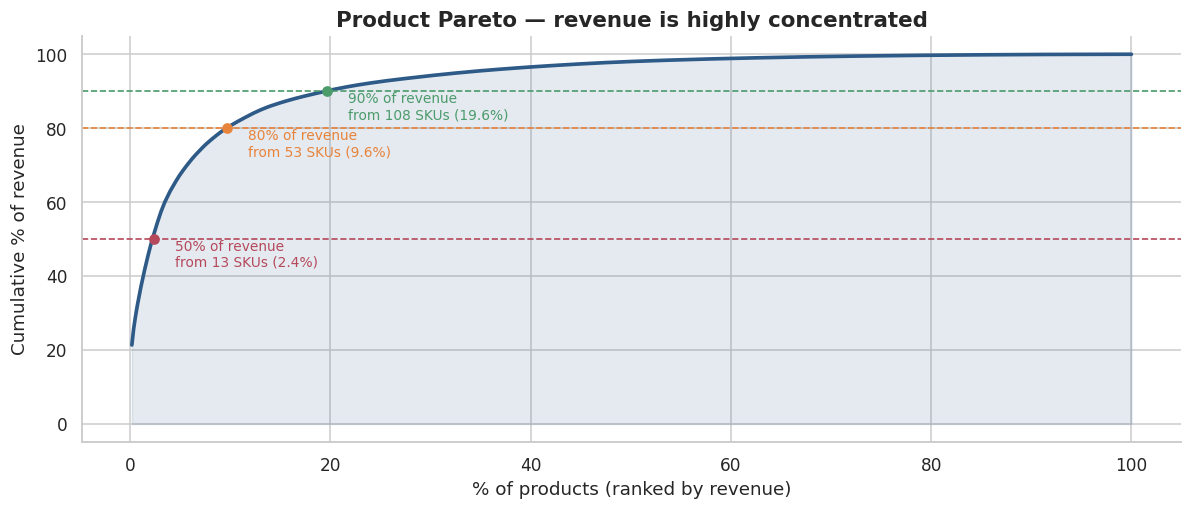

50% of revenue comes from  13 of 550 products (2.4%)
80% of revenue comes from  53 of 550 products (9.6%)
90% of revenue comes from 108 of 550 products (19.6%)


In [9]:
p = prod.sort_values("revenue", ascending=False).reset_index(drop=True)
p["cum_pct"] = p.revenue.cumsum() / p.revenue.sum() * 100
p["rank_pct"] = (p.index + 1) / len(p) * 100

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(p.rank_pct, p.cum_pct, color=PALETTE[0], lw=2.4)
ax.fill_between(p.rank_pct, p.cum_pct, alpha=.12, color=PALETTE[0])
for level, c in [(50, "#B5495B"), (80, "#E8833A"), (90, "#4B9B6B")]:
    n = int((p.cum_pct < level).sum()) + 1
    ax.axhline(level, color=c, ls="--", lw=1.1)
    ax.plot(n / len(p) * 100, level, "o", color=c)
    ax.annotate(f"{level}% of revenue\nfrom {n} SKUs ({n/len(p)*100:.1f}%)",
                (n / len(p) * 100, level), textcoords="offset points", xytext=(14, -18),
                fontsize=9, color=c)
ax.set_xlabel("% of products (ranked by revenue)"); ax.set_ylabel("Cumulative % of revenue")
ax.set_title("Product Pareto — revenue is highly concentrated")
plt.tight_layout(); plt.savefig(FIG / "06_product_pareto.png", bbox_inches="tight"); plt.show()

for level in (50, 80, 90):
    n = int((p.cum_pct < level).sum()) + 1
    print(f"{level}% of revenue comes from {n:>3} of {len(p)} products ({n/len(p)*100:.1f}%)")

## 6 · Q8 — The discount problem

This is the most actionable chart in the project.

Margin falls **monotonically** with discount depth and **crosses zero at 20%**. Above 20% discount,
every rupee of revenue destroys profit — the 20–25% band runs at −5.3% margin and the 25%+ band at
−14.2%, together losing ₹4.9 Cr of gross profit.

**34% of all line items carry a discount of 20% or more.**

The cause is structural: at an 8% blended margin, a 20% discount is not paid for by volume — it is
paid for out of margin that doesn't exist.

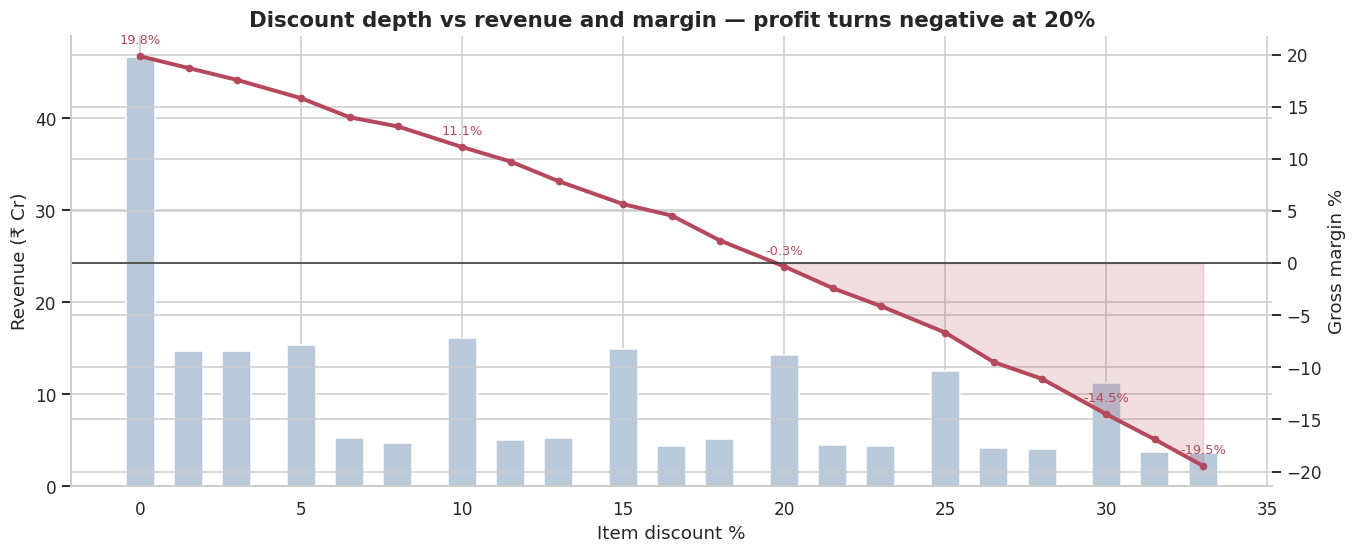

        lines  revenue  profit  margin_pct  rev_share
band                                                 
0%      41807     46.6    9.25       19.85       21.7
1-10%   68241     70.8   10.91       15.40       33.0
10-20%  52257     49.0    2.01        4.10       22.8
20-25%  25450     21.4   -1.13       -5.25       10.0
25%+    34496     26.8   -3.81      -14.23       12.5

Share of line items discounted 20%+: 34.1%
Profit destroyed by 25%+ discounting: ₹3.8 Cr


In [10]:
disc = (df[df.is_realised == 1]
        .groupby("discount_percentage", as_index=False)
        .agg(revenue=("line_revenue","sum"), profit=("line_profit","sum"),
             lines=("order_item_id","count"), units=("quantity","sum")))
disc["margin_pct"] = disc.profit / disc.revenue * 100
disc["rev_share"] = disc.revenue / disc.revenue.sum() * 100
disc = disc.sort_values("discount_percentage")

fig, ax1 = plt.subplots(figsize=(12.5, 5.2))
ax1.bar(disc.discount_percentage, disc.revenue/1e7, width=0.9, color="#B9C9DA", label="Revenue")
ax1.set_xlabel("Item discount %"); ax1.set_ylabel("Revenue (₹ Cr)")
ax1.set_title("Discount depth vs revenue and margin — profit turns negative at 20%")

ax2 = ax1.twinx()
ax2.plot(disc.discount_percentage, disc.margin_pct, color="#B5495B", lw=2.6, marker="o", ms=4)
ax2.axhline(0, color="#333", lw=1)
ax2.fill_between(disc.discount_percentage, disc.margin_pct, 0,
                 where=disc.margin_pct < 0, color="#B5495B", alpha=.18)
ax2.set_ylabel("Gross margin %")
ax2.spines["top"].set_visible(False)
for x, y in zip(disc.discount_percentage, disc.margin_pct):
    if x in (0, 10, 20, 30, 33):
        ax2.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=8.5, color="#B5495B")
plt.tight_layout(); plt.savefig(FIG / "07_discount_impact.png", bbox_inches="tight"); plt.show()

band = df[df.is_realised == 1].assign(
    band=lambda d: pd.cut(d.discount_percentage, [-.1, 0.1, 10, 20, 25, 40],
                          labels=["0%", "1-10%", "10-20%", "20-25%", "25%+"]))
bs = band.groupby("band", observed=True).agg(
    lines=("order_item_id","count"), revenue=("line_revenue","sum"), profit=("line_profit","sum"))
bs["margin_pct"] = (bs.profit / bs.revenue * 100).round(2)
bs["rev_share"] = (bs.revenue / bs.revenue.sum() * 100).round(1)
print(bs.assign(revenue=lambda x: (x.revenue/1e7).round(1),
                profit=lambda x: (x.profit/1e7).round(2)).to_string())
print(f"\nShare of line items discounted 20%+: "
      f"{(band.discount_percentage >= 20).mean()*100:.1f}%")
print(f"Profit destroyed by 25%+ discounting: ₹{-bs.loc['25%+','profit']/1e7:,.1f} Cr")

## 7 · Q4 — Regional performance

Demand is concentrated in South + North + West (88%). Two observations:

- **Every region has the same ~8% margin** — geography changes volume, not profitability. So regional
  strategy is a *distribution* question, not a pricing one.
- **Delayed delivery is 42–44% everywhere.** That is a company-wide operations problem, not a
  regional one.

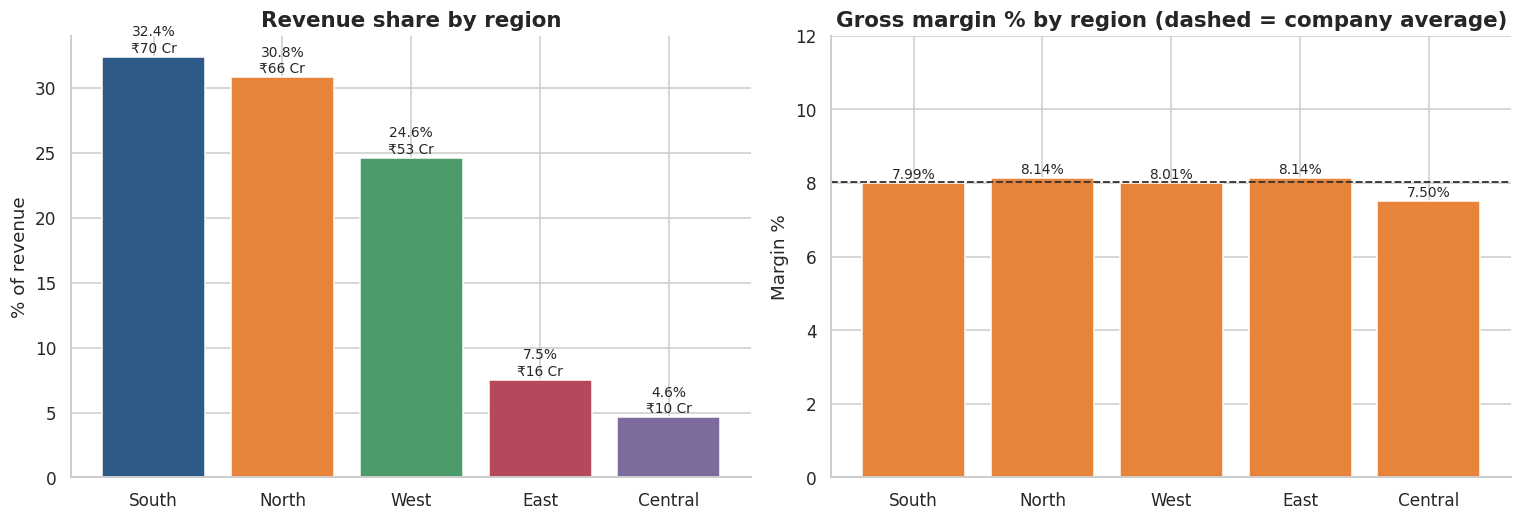

 region revenue      profit  orders  customers  delay  days  margin_pct      aov  rev_share
  South  ₹70 Cr 55550815.11   28518       8452   0.42  4.11        7.99 24384.83      32.39
  North  ₹66 Cr 53862310.35   26640       7913   0.43  4.10        8.14 24829.85      30.81
   West  ₹53 Cr 42314334.52   21393       6379   0.43  4.09        8.01 24706.64      24.62
   East  ₹16 Cr 13154112.52    6742       2125   0.44  4.14        8.14 23979.71       7.53
Central  ₹10 Cr  7466988.62    4067       1310   0.42  4.07        7.50 24484.50       4.64



Top 5 states by revenue:
delivery_state  revenue  orders  share
   Maharashtra     30.0   12334  13.99
 Uttar Pradesh     23.6    9327  10.98
       Gujarat     22.8    9059  10.63
     Karnataka     16.7    6966   7.78
    Tamil Nadu     16.2    6722   7.54


In [11]:
region = (df[df.is_realised == 1]
          .groupby("region", as_index=False)
          .agg(revenue=("line_revenue","sum"), profit=("line_profit","sum"),
               orders=("order_id","nunique"), customers=("customer_id","nunique"),
               delay=("delayed_flag","mean"), days=("delivery_days","mean")))
region["margin_pct"] = region.profit/region.revenue*100
region["aov"] = region.revenue/region.orders
region["rev_share"] = region.revenue/region.revenue.sum()*100
region = region.sort_values("revenue", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.9))
b = ax1.bar(region.region, region.rev_share, color=PALETTE[:5])
ax1.set_title("Revenue share by region"); ax1.set_ylabel("% of revenue")
for bar, v, rv in zip(b, region.rev_share, region.revenue):
    ax1.annotate(f"{v:.1f}%\n₹{rv/1e7:,.0f} Cr", (bar.get_x()+bar.get_width()/2, v),
                 textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)

ax2.bar(region.region, region.margin_pct, color=PALETTE[1])
ax2.axhline(region.profit.sum()/region.revenue.sum()*100, color="#333", ls="--", lw=1.2)
ax2.set_title("Gross margin % by region (dashed = company average)")
ax2.set_ylabel("Margin %"); ax2.set_ylim(0, 12)
for i, v in enumerate(region.margin_pct):
    ax2.annotate(f"{v:.2f}%", (i, v), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "08_region_performance.png", bbox_inches="tight"); plt.show()

show = region.copy()
show["revenue"] = show.revenue.map(lambda v: f"₹{v/1e7:,.0f} Cr")
print(show.round(2).to_string(index=False))

top_states = (df[df.is_realised == 1].groupby("delivery_state", as_index=False)
              .agg(revenue=("line_revenue","sum"), orders=("order_id","nunique")))
top_states["share"] = top_states.revenue/top_states.revenue.sum()*100
print("\nTop 5 states by revenue:")
print(top_states.nlargest(5,"revenue").assign(
    revenue=lambda x: (x.revenue/1e7).round(1)).round(2).to_string(index=False))

## 8 · Q6 / Q7 — Customers: value, repeat behaviour, percentile concentration

80% of buying customers are repeat customers, and they carry 95.6% of revenue — the base is healthy
and loyalty-driven, not a churn-and-burn acquisition machine.

But concentration is extreme: **the top 14.5% of customers (3,212 people) generate 50% of revenue**,
and 35.3% generate 80%.

One-time vs repeat:
          customers       revenue  avg_revenue  avg_orders  rev_share
repeat                                                               
One-time       4399  9.454719e+07     21492.88        1.00        4.4
Repeat        17809  2.052126e+09    115229.69        4.66       95.6

Repeat rate: 80.2%


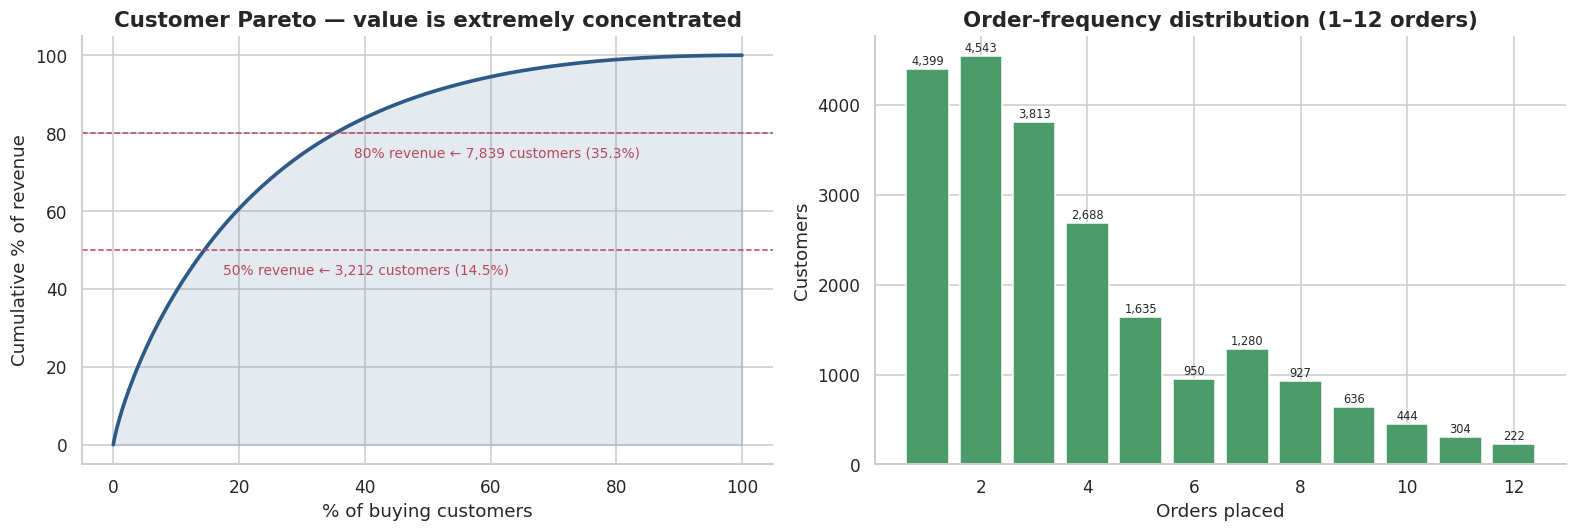


Customers for 50% of revenue: 3,212 (14.5%)
Customers for 80% of revenue: 7,839 (35.3%)

Top 20 customers hold ₹1.9 Cr (0.9% of revenue)


In [12]:
cust = (df[df.is_realised == 1]
        .groupby("customer_id", as_index=False)
        .agg(orders=("order_id","nunique"), revenue=("line_revenue","sum"),
             profit=("line_profit","sum"), first=("order_date","min"), last=("order_date","max")))
cust["aov"] = cust.revenue / cust.orders
cust["repeat"] = np.where(cust.orders > 1, "Repeat", "One-time")

summary = cust.groupby("repeat").agg(
    customers=("customer_id","count"), revenue=("revenue","sum"),
    avg_revenue=("revenue","mean"), avg_orders=("orders","mean"))
summary["rev_share"] = summary.revenue / summary.revenue.sum() * 100
print("One-time vs repeat:")
print(summary.round(2).to_string())
print(f"\nRepeat rate: {(cust.orders>1).mean()*100:.1f}%")

# Pareto
cs = cust.sort_values("revenue", ascending=False).reset_index(drop=True)
cs["cum_pct"] = cs.revenue.cumsum()/cs.revenue.sum()*100
cs["rank_pct"] = (cs.index+1)/len(cs)*100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5))

ax1.plot(cs.rank_pct, cs.cum_pct, color=PALETTE[0], lw=2.4)
ax1.fill_between(cs.rank_pct, cs.cum_pct, alpha=.12, color=PALETTE[0])
for level in (50, 80):
    n = int((cs.cum_pct < level).sum()) + 1
    ax1.axhline(level, color="#B5495B", ls="--", lw=1)
    ax1.annotate(f"{level}% revenue ← {n:,} customers ({n/len(cs)*100:.1f}%)",
                 (n/len(cs)*100, level), textcoords="offset points", xytext=(12, -16),
                 fontsize=9, color="#B5495B")
ax1.set_xlabel("% of buying customers"); ax1.set_ylabel("Cumulative % of revenue")
ax1.set_title("Customer Pareto — value is extremely concentrated")

freq = cust.groupby("orders").size().reset_index(name="customers")
freq = freq[freq.orders <= 12]
ax2.bar(freq.orders, freq.customers, color=PALETTE[2])
ax2.set_xlabel("Orders placed"); ax2.set_ylabel("Customers")
ax2.set_title("Order-frequency distribution (1–12 orders)")
for x, y in zip(freq.orders, freq.customers):
    ax2.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=7.5)
plt.tight_layout(); plt.savefig(FIG / "09_customer_pareto.png", bbox_inches="tight"); plt.show()

print(f"\nCustomers for 50% of revenue: {int((cs.cum_pct < 50).sum())+1:,} "
      f"({(int((cs.cum_pct < 50).sum())+1)/len(cs)*100:.1f}%)")
print(f"Customers for 80% of revenue: {int((cs.cum_pct < 80).sum())+1:,} "
      f"({(int((cs.cum_pct < 80).sum())+1)/len(cs)*100:.1f}%)")
print(f"\nTop 20 customers hold ₹{cs.head(20).revenue.sum()/1e7:,.1f} Cr "
      f"({cs.head(20).revenue.sum()/cs.revenue.sum()*100:.1f}% of revenue)")

### RFM segmentation

Five-quintile R/F/M scoring, then named segments. Recency is measured against the dataset end date
(2025-12-31) because "today" is fixed for this dataset.

**Champions + Loyal are 25.8% of customers but 46.2% of revenue.** "At Risk" and "Cannot Lose" hold
3,280 customers and ₹66 Cr of historical revenue — that is the win-back target list, and "At Risk"
alone is the largest single segment by revenue after Champions.

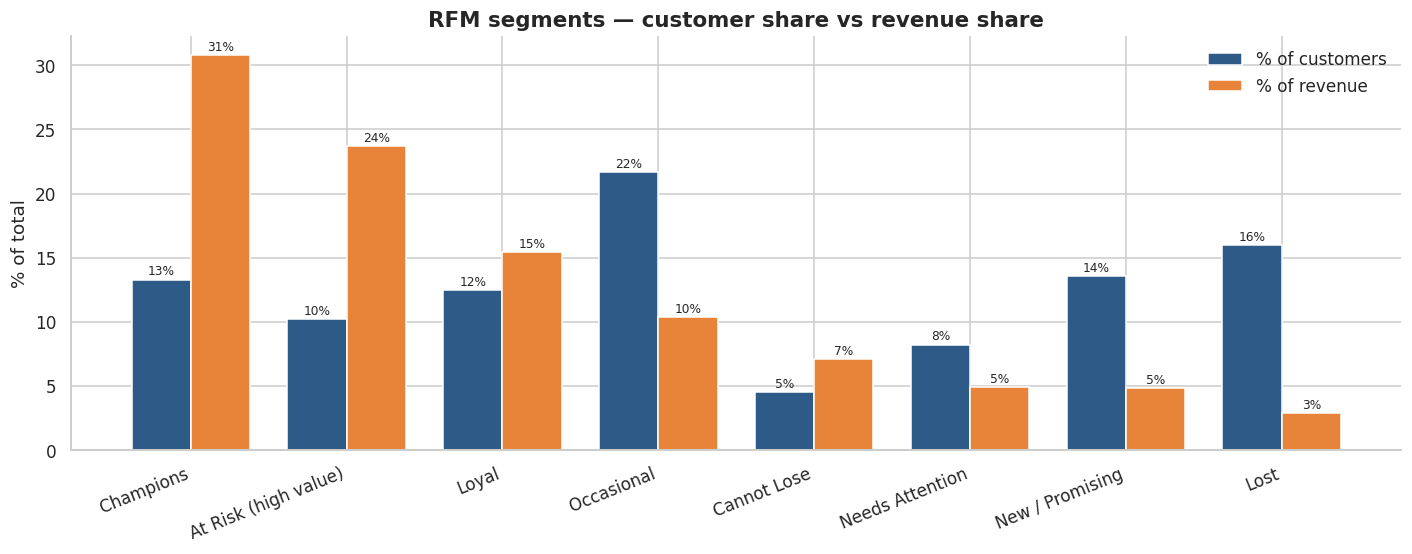

                segment  customers  revenue  avg_revenue  avg_orders  avg_recency  avg_rfm  pct_customers  pct_revenue
           1. Champions       2953 ₹66.0 Cr    223643.35        7.46        49.08     4.59          13.30        30.76
5. At Risk (high value)       2275 ₹50.9 Cr    223889.87        7.47       712.63     3.58          10.24        23.73
               2. Loyal       2766 ₹33.1 Cr    119665.56        6.03       203.16     3.82          12.45        15.42
          8. Occasional       4813 ₹22.3 Cr     46352.88        3.04       385.48     2.75          21.67        10.39
         6. Cannot Lose       1005 ₹15.2 Cr    151291.37        2.47       724.32     2.73           4.53         7.08
     4. Needs Attention       1827 ₹10.6 Cr     57971.19        2.56       300.70     2.71           8.23         4.93
     3. New / Promising       3016 ₹10.3 Cr     34240.37        1.55        63.19     2.65          13.58         4.81
                7. Lost       3553  ₹6.2 Cr     

In [13]:
BASE_DATE = pd.Timestamp("2025-12-31")
rfm = cust.copy()
rfm["recency_days"] = (BASE_DATE - rfm["last"]).dt.days
rfm["r"] = pd.qcut(rfm.recency_days.rank(method="first", ascending=False), 5, labels=[1,2,3,4,5]).astype(int)
rfm["f"] = pd.qcut(rfm.orders.rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["m"] = pd.qcut(rfm.revenue.rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["rfm_score"] = (rfm[["r","f","m"]].mean(axis=1)).round(2)

def label(row):
    r, f, m = row.r, row.f, row.m
    if r >= 4 and f >= 4 and m >= 4:              return "1. Champions"
    if r >= 3 and f >= 4:                          return "2. Loyal"
    if r >= 4 and f <= 2:                          return "3. New / Promising"
    if r == 3 and 2 <= f <= 3:                     return "4. Needs Attention"
    if r <= 2 and f >= 4 and m >= 4:               return "5. At Risk (high value)"
    if r <= 2 and m >= 4:                          return "6. Cannot Lose"
    if r <= 2 and f <= 2:                          return "7. Lost"
    return "8. Occasional"

rfm["segment"] = rfm.apply(label, axis=1)

seg = (rfm.groupby("segment")
       .agg(customers=("customer_id","count"), revenue=("revenue","sum"),
            avg_revenue=("revenue","mean"), avg_orders=("orders","mean"),
            avg_recency=("recency_days","mean"), avg_rfm=("rfm_score","mean"))
       .reset_index())
seg["pct_customers"] = seg.customers/seg.customers.sum()*100
seg["pct_revenue"] = seg.revenue/seg.revenue.sum()*100
seg = seg.sort_values("revenue", ascending=False)

fig, ax = plt.subplots(figsize=(13, 5.2))
xs = np.arange(len(seg)); w = 0.38
ax.bar(xs-w/2, seg.pct_customers, w, label="% of customers", color=PALETTE[0])
ax.bar(xs+w/2, seg.pct_revenue,  w, label="% of revenue",   color=PALETTE[1])
ax.set_xticks(xs); ax.set_xticklabels([s.split(". ")[1] for s in seg.segment], rotation=22, ha="right")
ax.set_ylabel("% of total")
ax.set_title("RFM segments — customer share vs revenue share")
ax.legend(frameon=False)
for i, (c, r) in enumerate(zip(seg.pct_customers, seg.pct_revenue)):
    ax.annotate(f"{c:.0f}%", (i-w/2, c), textcoords="offset points", xytext=(0,3), ha="center", fontsize=8)
    ax.annotate(f"{r:.0f}%", (i+w/2, r), textcoords="offset points", xytext=(0,3), ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "10_rfm_segments.png", bbox_inches="tight"); plt.show()

show = seg.copy()
show["revenue"] = show.revenue.map(lambda v: f"₹{v/1e7:,.1f} Cr")
print(show.round(2).to_string(index=False))
print(f"\nChampions+Loyal: {seg[seg.segment.str.startswith(('1.','2.'))].pct_customers.sum():.1f}% "
      f"of customers, {seg[seg.segment.str.startswith(('1.','2.'))].pct_revenue.sum():.1f}% of revenue")
risk = seg[seg.segment.str.startswith(('5.','6.'))]
print(f"At Risk + Cannot Lose: {risk.customers.sum():,} customers holding ₹{risk.revenue.sum()/1e7:,.1f} Cr")

## 9 · Cohort retention

Cohorts are defined by first purchase month. Because the dataset ends 2025-12-31, only cohorts with a
complete 12-month observation window are meaningful — later cohorts are truncated.

**The curve decays hard: 31.5% of a cohort buys again the following month, and by month 12 only 6.8%
are still active (cohort range 2.7%–11.2%).** That is normal for marketplace retail — but it means the
"80% repeat rate" is a long tail of low-frequency buyers, not a retained core. The commercial
opportunity is **re-activation**, not retention: most lapsed customers did not defect, they simply
stopped being prompted.

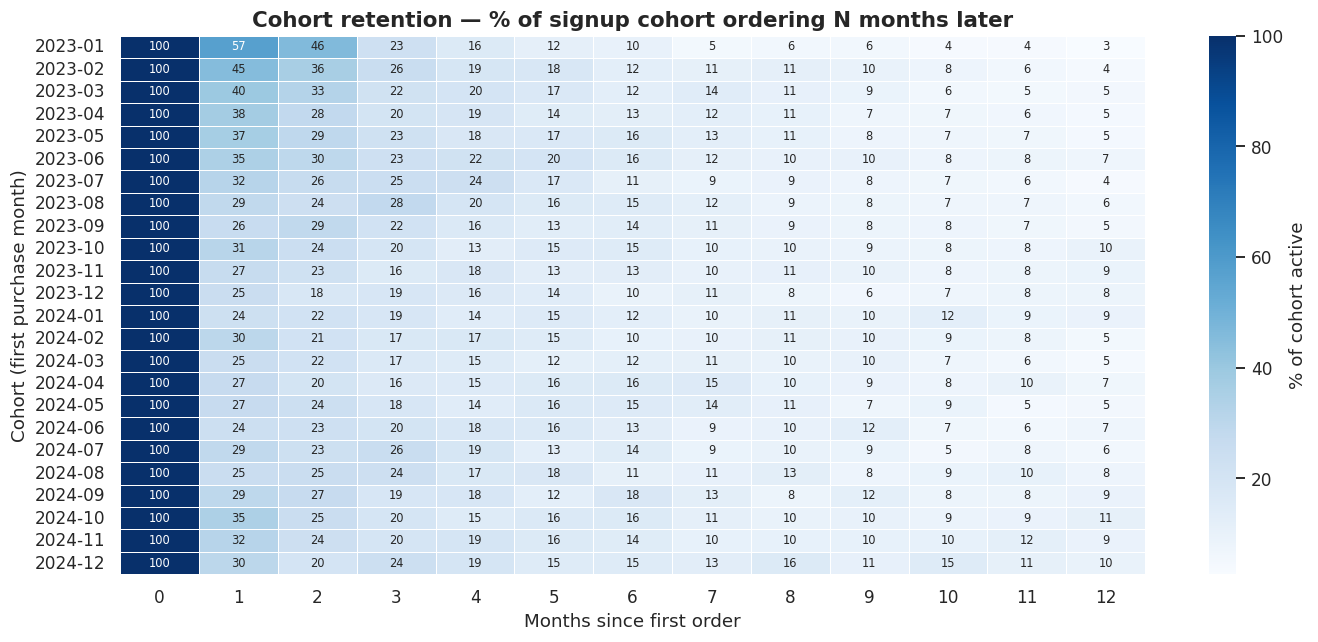

Average retention curve:
  month  0: 100.0%
  month  1: 31.5%
  month  3: 21.0%
  month  6: 13.4%
  month  9: 9.0%
  month 12: 6.8%

Month-12 retention range across cohorts: 2.7% – 11.2%


In [14]:
first = df[df.is_realised == 1].groupby("customer_id").order_date.min().rename("first_order")
act = df[df.is_realised == 1][["customer_id","order_date"]].copy()
act["cohort"] = act.customer_id.map(first).dt.strftime("%Y-%m")
act["offset"] = ((act.order_date.dt.year - act.customer_id.map(first).dt.year) * 12
                 + (act.order_date.dt.month - act.customer_id.map(first).dt.month))
sizes = act.groupby("cohort").customer_id.nunique()
mat = (act[act.offset.between(0, 12)]
       .groupby(["cohort","offset"]).customer_id.nunique().unstack(fill_value=0))
retention = mat.div(sizes, axis=0) * 100

# keep cohorts with a full 12-month window
full = retention[retention.index <= "2024-12"]

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(full, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of cohort active"},
            linewidths=.4, linecolor="white", ax=ax, annot_kws={"fontsize": 7.5})
ax.set_title("Cohort retention — % of signup cohort ordering N months later")
ax.set_xlabel("Months since first order"); ax.set_ylabel("Cohort (first purchase month)")
plt.tight_layout(); plt.savefig(FIG / "11_cohort_retention.png", bbox_inches="tight"); plt.show()

curve = full.mean(axis=0)
print("Average retention curve:")
for m in [0, 1, 3, 6, 9, 12]:
    if m in curve.index:
        print(f"  month {m:>2}: {curve[m]:.1f}%")
print(f"\nMonth-12 retention range across cohorts: {full[12].min():.1f}% – {full[12].max():.1f}%")

## 10 · Payments, channels and delivery

Three quick operational reads:

- **UPI is 32% of revenue** — the payment mix is digital-first, with COD still 17%.
- **Organic Search is the largest acquisition channel**; Email Marketing carries a visibly lower
  margin (6.95% vs 8.1%) worth investigating.
- **Delivery delay runs at 42% overall** and is worst on Standard (54.9%) — the cheap shipping tier
  is where the service promise breaks.

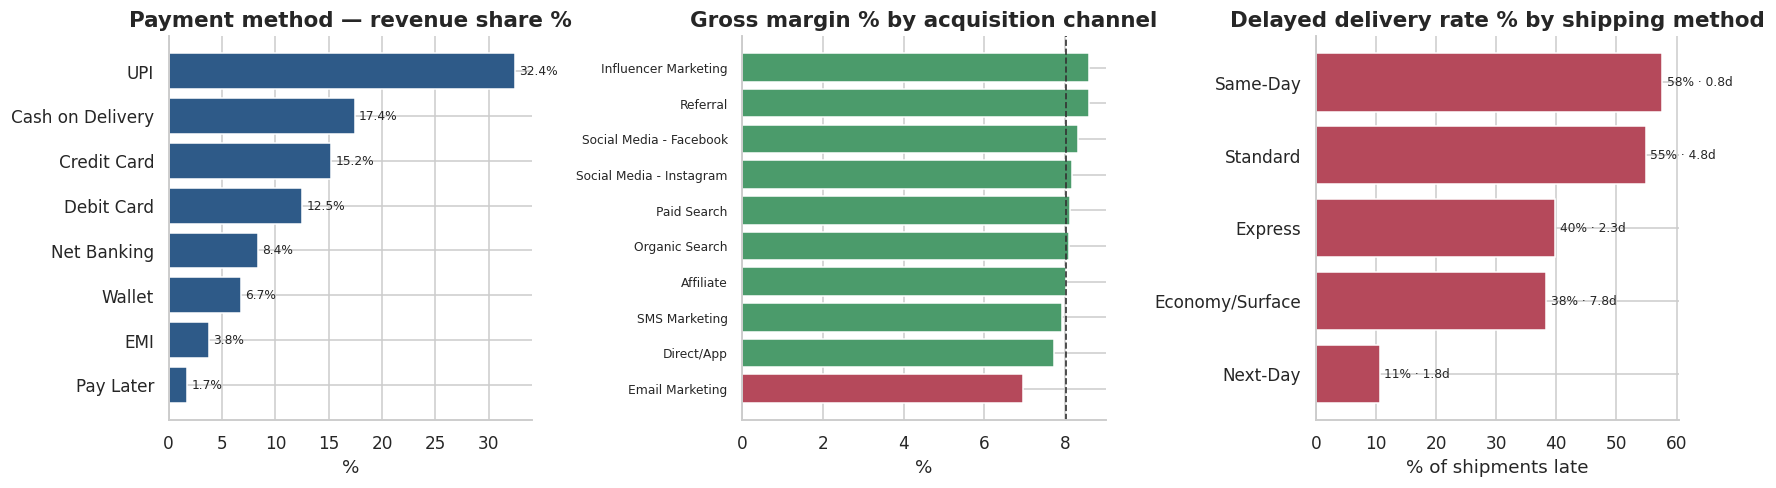

Overall delayed delivery rate: 42.8%
Average delivery days: 4.10


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

pay = (df[df.is_realised == 1].groupby("payment_method", as_index=False)
       .agg(revenue=("line_revenue","sum"), orders=("order_id","nunique")))
pay["share"] = pay.revenue/pay.revenue.sum()*100
pay = pay.sort_values("share", ascending=True).tail(8)
axes[0].barh(pay.payment_method, pay.share, color=PALETTE[0])
axes[0].set_title("Payment method — revenue share %"); axes[0].set_xlabel("%")
for i, v in enumerate(pay.share):
    axes[0].text(v+0.4, i, f"{v:.1f}%", va="center", fontsize=8)

ch = (df[df.is_realised == 1].groupby("marketing_channel", as_index=False)
      .agg(revenue=("line_revenue","sum"), profit=("line_profit","sum")))
ch["margin_pct"] = ch.profit/ch.revenue*100
ch = ch.sort_values("margin_pct")
cols = ["#B5495B" if m < 7.5 else "#4B9B6B" for m in ch.margin_pct]
axes[1].barh(ch.marketing_channel, ch.margin_pct, color=cols)
axes[1].axvline(ch.profit.sum()/ch.revenue.sum()*100, color="#333", ls="--", lw=1.1)
axes[1].set_title("Gross margin % by acquisition channel"); axes[1].set_xlabel("%")
axes[1].tick_params(axis="y", labelsize=8)

ship = (df[(df.is_realised == 1) & df.delivery_days.notna()]
        .groupby("shipping_method", as_index=False)
        .agg(delay=("delayed_flag","mean"), days=("delivery_days","mean"),
             orders=("order_id","nunique")))
ship = ship.sort_values("delay")
axes[2].barh(ship.shipping_method, ship.delay*100, color=PALETTE[3])
axes[2].set_title("Delayed delivery rate % by shipping method")
axes[2].set_xlabel("% of shipments late")
for i, (d, dy) in enumerate(zip(ship.delay*100, ship.days)):
    axes[2].text(d+0.8, i, f"{d:.0f}% · {dy:.1f}d", va="center", fontsize=8)

plt.tight_layout(); plt.savefig(FIG / "12_payments_channels_delivery.png", bbox_inches="tight"); plt.show()

print(f"Overall delayed delivery rate: "
      f"{df.loc[(df.is_realised==1) & df.delayed_flag.notna(),'delayed_flag'].mean()*100:.1f}%")
print(f"Average delivery days: {df.loc[df.delivery_days.notna(),'delivery_days'].mean():.2f}")

## 11 · Findings and what management should do

### What the data shows

| # | Finding | Number |
|---|---|---|
| 1 | Realised revenue / gross profit | ₹2.147 Bn / ₹172 M |
| 2 | Blended gross margin | 8.03% |
| 3 | Electronics: revenue share vs margin | 50.0% of revenue, 0.67% margin |
| 4 | Fashion: revenue share vs margin | 5.7% of revenue, 33.2% margin |
| 5 | Single largest SKU share of revenue | 21.4% at 1.45% margin |
| 6 | Discount level where profit turns negative | 20% |
| 7 | Line items discounted ≥20% (loss-making) | 34.1%, −₹4.9 Cr of profit |
| 8 | Repeat customers: share of customers / revenue | 80.2% / 95.6% |
| 9 | Customers generating 50% of revenue | 14.5% (3,212) |
| 10 | Q4 share of 3-year revenue | 36.9% pooled; Q4-2025 alone = 20.1% |
| 11 | December vs January revenue per trading day | 2.46× |
| 12 | Delayed delivery rate | 42.8% |
| 13 | Month-12 cohort activity | 6.8% |
| 14 | Lost revenue from cancellations + failures | ₹261 M (10.7% of total demand) |

### What I would recommend

**1. Cap discounting at 15%.** Margin crosses zero at 20% and 34% of line items sit at or above it.
Those lines currently lose ₹4.9 Cr of gross profit. Repricing them to the 15% band (which holds a
4.1% margin) would recover roughly **₹7 Cr before any volume effect** — and the volume effect cannot
be estimated from this data, so this is a directional, testable hypothesis rather than a guaranteed
saving. Run it as an A/B / holdout test on a product subset first.

**2. Fix the premium-electronics economics, don't chase the revenue.** Electronics is 50% of revenue
and 0.67% of margin. Options: renegotiate cost (currently 85.8% of list on the top SKU), stop
discounting thin-margin SKUs, or shift mix toward accessories with 20%+ margins.

**3. Rebalance toward Fashion / Footwear / Bags / Home & Kitchen.** These four are 17.7% of revenue but
~58% of gross profit. They are where incremental marketing spend earns the most.

**4. Treat the top 13 SKUs as critical infrastructure.** 2.4% of products make 50% of revenue. Stock-out
risk here is company-level revenue risk, not a category problem.

**5. Attack delivery delay.** 42.8% late is a satisfaction and returns driver (returns run 3.1–9.4% by
category). Standard shipping is the worst tier at 54.9% late.

**6. Build a re-activation programme, not a retention programme.** Only 31.5% of a cohort buys again in
month 2 and 6.8% by month 12. The larger prize is prompting the long tail of one-and-done buyers —
4,399 customers who bought exactly once and never returned.

### Limitations

- This is **synthetic data**; relationships are simulated, so effect sizes are indicative not causal.
- Revenue is merchandise-only (excludes shipping and tax), so it understates cash collected.
- Recency and churn status are measured to a fixed 2025-12-31 cutoff.
- No cost data for marketing beyond campaign-level aggregates, so CAC/ROI by customer is not derivable.
- Discount→volume elasticity cannot be estimated: the data has no pre/post price experiment.